# RQ1 extension — prevalence-normalized AP and shared-test score diagnostics

This notebook extends **RQ1: task/evidence definition** without reopening the entire analysis.

It addresses two unresolved points:

1. **Raw `AP_gain = AP - prevalence` is not directly comparable across tasks with very different prevalence**, because the maximum attainable gain is `1 - prevalence`.
2. In the shared-test analysis, `hard → mixed` showed a much larger change in MCC than in AP. We therefore need to determine whether task formulation changes:
   - ranking/discrimination,
   - the operating point / predicted-positive fraction,
   - or both.

The extension adds:

- normalized AP skill;
- shared-test ROC-AUC;
- shared-test AP skill;
- predicted-positive fraction;
- positive/negative score-distribution summaries;
- score shifts between matched task formulations;
- direct comparison of threshold-free vs threshold-dependent effects.

The supervised methodological contract already requires AP to be contextualized by prevalence and includes ROC-AUC and predicted-positive fraction among the binary diagnostics.

## Normalized AP skill

For positive prevalence \(p\),

\[
AP_{\mathrm{skill}} = \frac{AP-p}{1-p}.
\]

Interpretation:

- random ranking baseline: approximately `0`;
- perfect ranking: `1`;
- values below `0`: worse than the prevalence baseline;
- unlike raw `AP_gain`, the available headroom is normalized.

This is a **supporting cross-task diagnostic**, not a replacement for MCC as the primary supervised metric.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    matthews_corrcoef,
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
)

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 200)

GLOBAL_TASKS = ["global_easy", "global_hard", "global_mixed"]
TASK_PAIRS = [
    ("global_easy", "global_mixed"),
    ("global_hard", "global_mixed"),
]

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "results/analysis_supervised/stage12a").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the PhageLysClass project root.")

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

expected = pd.read_csv(
    STAGE12A / "expected_experiment_registry.tsv",
    sep="\t",
    low_memory=False,
)

global_df = master[master["task"].isin(GLOBAL_TASKS)].copy()

print("Global supervised families:", len(global_df))
print("Representations:", sorted(global_df["representation"].unique()))
print("Algorithms:", sorted(global_df["algorithm"].unique()))
display(global_df.head())

Global supervised families: 960
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']


,experiment_id,task,task_type,R,S,representation,algorithm,selected_config,mcc,ap,ap_baseline,ap_gain,roc_auc,f1,precision,recall,specificity,balanced_accuracy,brier,log_loss,threshold,prevalence,predicted_positive_fraction,tp,tn,fp,fn,n,n_positive,n_negative,runtime__experiment_id,runtime__validation_and_final_wall_seconds,runtime__final_fit_seconds,runtime__final_test_prediction_seconds,runtime__process_peak_rss_kb_start,runtime__process_peak_rss_kb_end,runtime__representation_dimension,runtime__representation_sparse,runtime__n_outer_train,runtime__n_inner_train,runtime__n_validation,runtime__n_outer_test,macro_f1,macro_precision,macro_recall,weighted_f1
0,SUP__global_easy__R90__S90__roxy_48__LR,global_easy,binary,90,90,roxy_48,LR,LR02,0.511638,0.624507,0.159129,0.465379,0.885363,0.584242,0.453985,0.819319,0.813519,0.816419,0.133556,0.424512,0.5,0.159129,0.287183,1179.0,6186.0,1418.0,260.0,9043,1439.0,7604.0,SUP__global_easy__R90__S90__roxy_48__LR,6.706161,1.509784,0.105969,1065884,1122972,48,False,21049,16839,4210,9043,NaN,NaN,NaN,NaN
1,SUP__global_easy__R90__S90__roxy_48__RF,global_easy,binary,90,90,roxy_48,RF,RF02,0.708529,0.856043,0.159129,0.696914,0.954596,0.733960,0.890873,0.624044,0.985534,0.804789,0.056051,0.199629,0.5,0.159129,0.111467,898.0,7494.0,110.0,541.0,9043,1439.0,7604.0,SUP__global_easy__R90__S90__roxy_48__RF,18.685276,5.835726,0.132416,1108588,1209316,48,False,21049,16839,4210,9043,NaN,NaN,NaN,NaN
2,SUP__global_easy__R90__S90__roxy_48__KNN,global_easy,binary,90,90,roxy_48,KNN,KNN02,0.770957,0.852350,0.159129,0.693221,0.937909,0.802239,0.866237,0.747047,0.978169,0.862608,0.046178,0.692643,0.5,0.159129,0.137233,1075.0,7438.0,166.0,364.0,9043,1439.0,7604.0,SUP__global_easy__R90__S90__roxy_48__KNN,3.828289,0.014279,1.427826,1209316,3069900,48,False,21049,16839,4210,9043,NaN,NaN,NaN,NaN
3,SUP__global_easy__R90__S90__roxy_48__XGB,global_easy,binary,90,90,roxy_48,XGB,XGB02,0.772730,0.886425,0.159129,0.727296,0.962457,0.808895,0.808895,0.808895,0.963835,0.886365,0.046277,0.164263,0.5,0.159129,0.159129,1164.0,7329.0,275.0,275.0,9043,1439.0,7604.0,SUP__global_easy__R90__S90__roxy_48__XGB,7.947027,2.909099,0.067628,1088680,1231832,48,False,21049,16839,4210,9043,NaN,NaN,NaN,NaN
4,SUP__global_easy__R90__S90__roxy_48__MLP,global_easy,binary,90,90,roxy_48,MLP,MLP02,0.774161,0.877357,0.159129,0.718229,0.956783,0.810345,0.804244,0.816539,0.962388,0.889464,0.054094,0.401434,0.5,0.159129,0.161561,1175.0,7318.0,286.0,264.0,9043,1439.0,7604.0,SUP__global_easy__R90__S90__roxy_48__MLP,172.201589,56.859166,0.083260,1231832,1231832,48,False,21049,16839,4210,9043,NaN,NaN,NaN,NaN


## 1. Derive prevalence robustly and compute native-test AP skill

In [3]:
def find_prevalence_column(df):
    candidates = [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]
    return next((c for c in candidates if c in df.columns), None)

def derive_prevalence(df):
    pcol = find_prevalence_column(df)

    if pcol is not None:
        return pd.to_numeric(df[pcol], errors="coerce"), pcol

    # Fallbacks from counts.
    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = pd.to_numeric(df["tp"], errors="coerce") + pd.to_numeric(df["fn"], errors="coerce")
        n = (
            pos
            + pd.to_numeric(df["tn"], errors="coerce")
            + pd.to_numeric(df["fp"], errors="coerce")
        )
        return pos / n, "derived_from_confusion_counts"

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    raise KeyError(
        "Could not identify or derive test prevalence from supervised_master_results.tsv."
    )

prevalence, prevalence_source = derive_prevalence(global_df)
global_df["prevalence_for_ap"] = prevalence

if "ap" not in global_df.columns:
    raise KeyError("Column 'ap' is required for this notebook.")

denom = 1.0 - global_df["prevalence_for_ap"]
global_df["ap_skill"] = np.where(
    denom > 0,
    (global_df["ap"] - global_df["prevalence_for_ap"]) / denom,
    np.nan,
)

global_df["ap_gain_recomputed"] = (
    global_df["ap"] - global_df["prevalence_for_ap"]
)

print("Prevalence source:", prevalence_source)
print("AP-skill finite:", np.isfinite(global_df["ap_skill"]).sum(), "/", len(global_df))
print("AP-skill range:", global_df["ap_skill"].min(), "to", global_df["ap_skill"].max())

Prevalence source: prevalence
AP-skill finite: 960 / 960
AP-skill range: 0.3043239764562362 to 0.9953564201729957


In [4]:
native_ap_summary = (
    global_df.groupby("task", as_index=False)
    .agg(
        prevalence_mean=("prevalence_for_ap", "mean"),
        prevalence_median=("prevalence_for_ap", "median"),
        ap_mean=("ap", "mean"),
        ap_median=("ap", "median"),
        ap_gain_mean=("ap_gain_recomputed", "mean"),
        ap_gain_median=("ap_gain_recomputed", "median"),
        ap_skill_mean=("ap_skill", "mean"),
        ap_skill_median=("ap_skill", "median"),
        ap_skill_min=("ap_skill", "min"),
        ap_skill_max=("ap_skill", "max"),
    )
)

display(native_ap_summary)

,task,prevalence_mean,prevalence_median,ap_mean,ap_median,ap_gain_mean,ap_gain_median,ap_skill_mean,ap_skill_median,ap_skill_min,ap_skill_max
0,global_easy,0.166521,0.162461,0.799049,0.856390,0.632528,0.685801,0.758482,0.827051,0.306060,0.985315
1,global_hard,0.692900,0.691797,0.989592,0.992753,0.296692,0.292053,0.966808,0.976635,0.844828,0.995356
2,global_mixed,0.150964,0.149552,0.791112,0.846885,0.640148,0.694360,0.753712,0.820476,0.304324,0.985125


### Compare raw AP, raw AP gain, and normalized AP skill

If `global_hard` has high prevalence, raw `AP_gain` can look artificially compressed because its maximum possible value is only `1-p`. `AP_skill` removes that changing headroom.

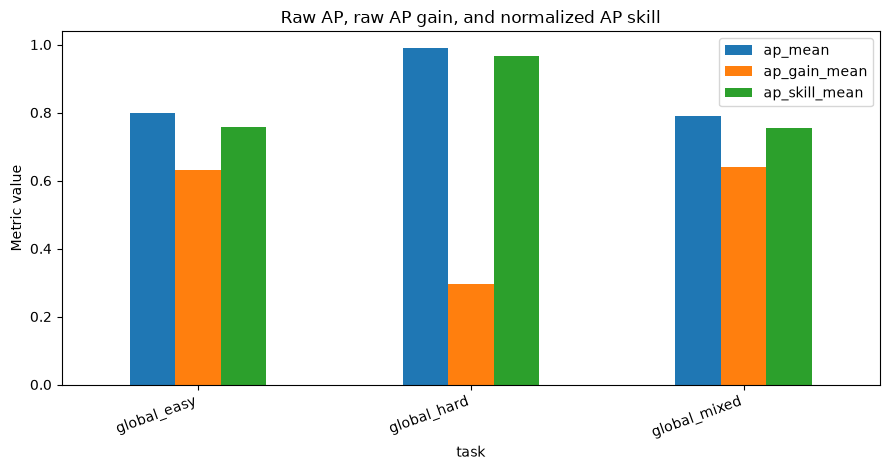

In [5]:
plot_summary = native_ap_summary.set_index("task")[
    ["ap_mean", "ap_gain_mean", "ap_skill_mean"]
]

plot_summary.plot(kind="bar", figsize=(9, 4.8))
plt.ylabel("Metric value")
plt.title("Raw AP, raw AP gain, and normalized AP skill")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 2. Matched-factor task contrasts using AP skill

In [6]:
keys = ["R", "S", "representation", "algorithm"]

ap_skill_pivot = global_df.pivot_table(
    index=keys,
    columns="task",
    values="ap_skill",
    aggfunc="first",
).reset_index()

required = set(GLOBAL_TASKS)
if not required <= set(ap_skill_pivot.columns):
    raise RuntimeError("Not all three global tasks were recovered in the AP-skill pivot.")

ap_skill_pivot["hard_minus_easy"] = (
    ap_skill_pivot["global_hard"] - ap_skill_pivot["global_easy"]
)
ap_skill_pivot["mixed_minus_easy"] = (
    ap_skill_pivot["global_mixed"] - ap_skill_pivot["global_easy"]
)
ap_skill_pivot["hard_minus_mixed"] = (
    ap_skill_pivot["global_hard"] - ap_skill_pivot["global_mixed"]
)

ap_skill_contrasts = []

for contrast in [
    "hard_minus_easy",
    "mixed_minus_easy",
    "hard_minus_mixed",
]:
    x = ap_skill_pivot[contrast].dropna()

    ap_skill_contrasts.append(
        {
            "contrast": contrast,
            "n": len(x),
            "mean_delta_ap_skill": x.mean(),
            "median_delta_ap_skill": x.median(),
            "q25": x.quantile(0.25),
            "q75": x.quantile(0.75),
            "min": x.min(),
            "max": x.max(),
            "fraction_positive": (x > 0).mean(),
            "fraction_negative": (x < 0).mean(),
        }
    )

display(pd.DataFrame(ap_skill_contrasts))

,contrast,n,mean_delta_ap_skill,median_delta_ap_skill,q25,q75,min,max,fraction_positive,fraction_negative
0,hard_minus_easy,320,0.208326,0.153011,0.049094,0.359905,0.002102,0.624622,1.000000,0.000000
1,mixed_minus_easy,320,-0.004770,-0.004817,-0.017459,0.007879,-0.107838,0.112220,0.359375,0.640625
2,hard_minus_mixed,320,0.213096,0.158137,0.058538,0.369813,0.002292,0.626358,1.000000,0.000000


task           hard_minus_easy                                         mixed_minus_easy                                         hard_minus_mixed                                \
                          mean    median       std       min       max             mean    median       std       min       max             mean    median       std       min   
representation                                                                                                                                                                   
esm2_t30_150m         0.028066  0.023911  0.019058  0.002102  0.086891        -0.008447 -0.006649  0.009699 -0.044243  0.012182         0.036513  0.033423  0.020776  0.002292   
esm2_t6_8m            0.096323  0.089966  0.038703  0.026914  0.193189        -0.008161 -0.004839  0.023426 -0.086145  0.043582         0.104484  0.102490  0.043569  0.031520   
onehot_1024           0.446217  0.475863  0.098770  0.179520  0.624622        -0.004303 -0.007556  0.032565 -0.094617  0.112220         0.450520  0.479368  0.099623  0.169698   
roxy_48               0.262699  0.237988  0.102761  0.118299  0.503424         0.001832  0.003595  0.031993 -0.107838  0.085665         0.260867  0.245692  0.101244  0.103457   

task                      
                     max  
representation            
esm2_t30_150m   0.088688  
esm2_t6_8m      0.205862  
onehot_1024     0.626358  
roxy_48         0.519085

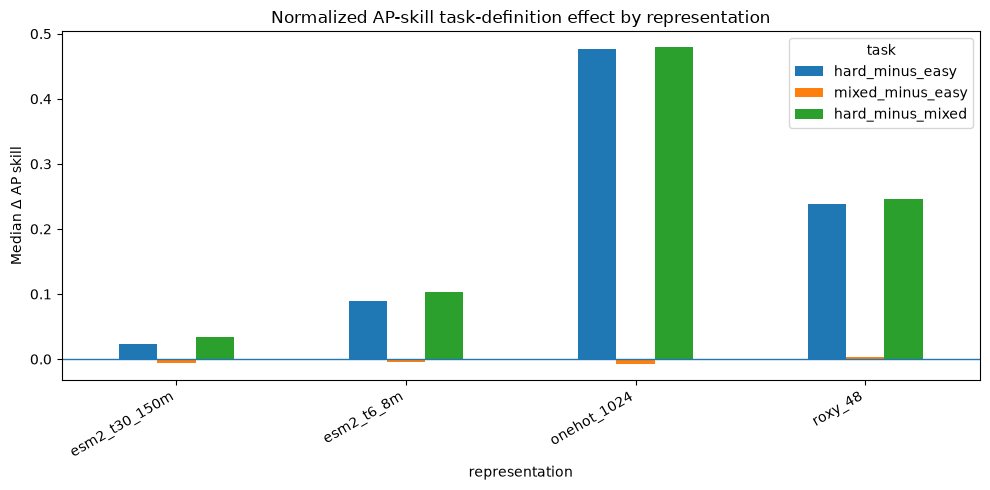

In [7]:
# AP-skill task-definition effect by representation.
rep_ap_skill_effect = (
    ap_skill_pivot.groupby("representation")[
        ["hard_minus_easy", "mixed_minus_easy", "hard_minus_mixed"]
    ]
    .agg(["mean", "median", "std", "min", "max"])
)

display(rep_ap_skill_effect)

ap_skill_pivot.groupby("representation")[
    ["hard_minus_easy", "mixed_minus_easy", "hard_minus_mixed"]
].median().plot(kind="bar", figsize=(10, 5))

plt.axhline(0, linewidth=1)
plt.ylabel("Median Δ AP skill")
plt.title("Normalized AP-skill task-definition effect by representation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 3. AP-skill surfaces over the complete R×S factorial


 hard_minus_easy


S,90,70,50,30
R,,,,
90,0.101881,0.106833,0.115031,0.135732
70,0.123067,0.113988,0.151919,0.163424
50,0.185581,0.167180,0.162339,0.174334
30,0.196549,0.218021,0.192023,0.199609


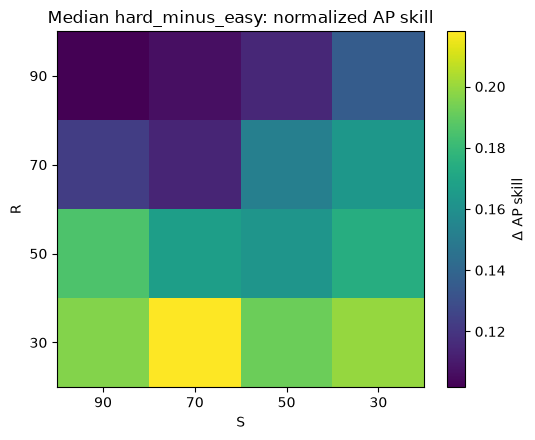


 mixed_minus_easy


S,90,70,50,30
R,,,,
90,-0.003011,0.003547,-0.006123,0.008361
70,-0.005986,-0.006655,-0.004181,-0.016779
50,0.010579,-0.020284,-0.005404,-0.014791
30,-0.003525,0.006344,-0.017392,-0.019801


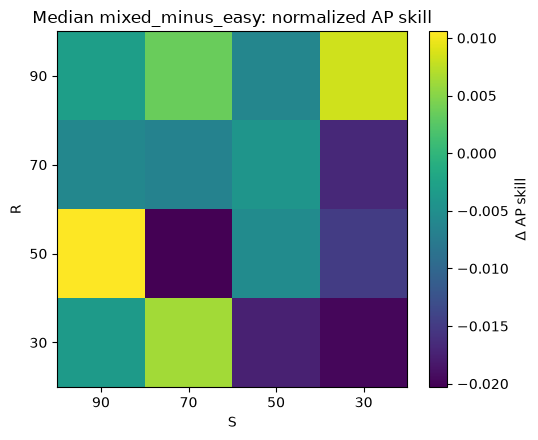


 hard_minus_mixed


S,90,70,50,30
R,,,,
90,0.105278,0.095615,0.119381,0.125514
70,0.126424,0.122077,0.156494,0.188656
50,0.165039,0.188292,0.171053,0.206035
30,0.191143,0.195452,0.226135,0.223373


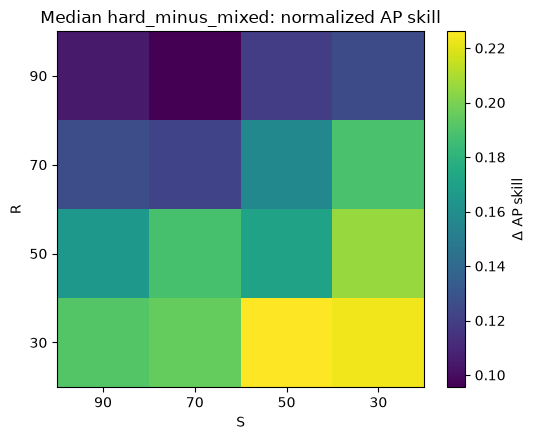

In [8]:
for contrast in [
    "hard_minus_easy",
    "mixed_minus_easy",
    "hard_minus_mixed",
]:
    surface = (
        ap_skill_pivot
        .groupby(["R", "S"])[contrast]
        .median()
        .reset_index()
        .pivot(index="R", columns="S", values=contrast)
        .reindex(index=R_LEVELS, columns=S_LEVELS)
    )

    print("\n", contrast)
    display(surface)

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(surface.to_numpy(), aspect="auto")
    ax.set_xticks(range(len(S_LEVELS)), S_LEVELS)
    ax.set_yticks(range(len(R_LEVELS)), R_LEVELS)
    ax.set_xlabel("S")
    ax.set_ylabel("R")
    ax.set_title(f"Median {contrast}: normalized AP skill")
    plt.colorbar(im, ax=ax, label="Δ AP skill")
    plt.tight_layout()
    plt.show()

# 4. Extended shared-test analysis

We now recalculate metrics on identical test entities for:

- `global_easy → global_mixed`
- `global_hard → global_mixed`

The shared subset keeps only entities with the **same biological label in both task formulations**.

New diagnostics:

- MCC;
- balanced accuracy;
- AP;
- normalized AP skill;
- ROC-AUC;
- predicted-positive fraction at the frozen `0.5` threshold;
- positive and negative score means/medians/quantiles;
- score correlation and mean absolute score shift between the two models.

This lets us distinguish:

> **ranking/discrimination change**

from

> **threshold/operating-point change**.

In [9]:
SCORE_CANDIDATES = [
    "score_positive",
    "y_score",
    "y_prob",
    "probability",
    "positive_probability",
]

PRED_CANDIDATES = [
    "y_pred",
    "prediction",
    "predicted_label",
]

def detect_score_column(df):
    for c in SCORE_CANDIDATES:
        if c in df.columns:
            return c
    raise KeyError(f"No positive score column found. Columns: {list(df.columns)}")

def detect_pred_column(df):
    return next((c for c in PRED_CANDIDATES if c in df.columns), None)

def ap_skill(ap, prevalence):
    if not np.isfinite(ap) or not np.isfinite(prevalence) or prevalence >= 1:
        return np.nan
    return (ap - prevalence) / (1.0 - prevalence)

def summarize_scores(y, score):
    y = np.asarray(y).astype(int)
    score = np.asarray(score).astype(float)

    out = {}

    for label, name in [(1, "positive"), (0, "negative")]:
        x = score[y == label]
        if len(x):
            out[f"{name}_score_mean"] = float(np.mean(x))
            out[f"{name}_score_median"] = float(np.median(x))
            out[f"{name}_score_q10"] = float(np.quantile(x, 0.10))
            out[f"{name}_score_q25"] = float(np.quantile(x, 0.25))
            out[f"{name}_score_q75"] = float(np.quantile(x, 0.75))
            out[f"{name}_score_q90"] = float(np.quantile(x, 0.90))
        else:
            for suffix in ["mean", "median", "q10", "q25", "q75", "q90"]:
                out[f"{name}_score_{suffix}"] = np.nan

    return out

def binary_metrics(y_true, score, y_pred=None):
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score).astype(float)

    if y_pred is None:
        y_pred = (score >= 0.5).astype(int)
    else:
        y_pred = np.asarray(y_pred).astype(int)

    prevalence = float(np.mean(y_true))

    out = {
        "n": len(y_true),
        "n_positive": int(np.sum(y_true == 1)),
        "n_negative": int(np.sum(y_true == 0)),
        "prevalence": prevalence,
        "predicted_positive_fraction": float(np.mean(y_pred == 1)),
        "mean_score": float(np.mean(score)),
        "median_score": float(np.median(score)),
    }

    if len(np.unique(y_true)) < 2:
        out.update(
            {
                "mcc": np.nan,
                "balanced_accuracy": np.nan,
                "ap": np.nan,
                "ap_skill": np.nan,
                "roc_auc": np.nan,
            }
        )
        out.update(summarize_scores(y_true, score))
        return out

    ap = average_precision_score(y_true, score)

    out.update(
        {
            "mcc": matthews_corrcoef(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "ap": ap,
            "ap_skill": ap_skill(ap, prevalence),
            "roc_auc": roc_auc_score(y_true, score),
        }
    )

    out.update(summarize_scores(y_true, score))
    return out

In [10]:
CACHE_PATH = CACHE_DIR / "rq1_extended_shared_test_diagnostics.tsv"
FORCE_RECOMPUTE = False

def build_extended_shared_test():
    exp_paths = expected[["experiment_id", "expected_path"]].copy()
    gmaster = global_df.merge(exp_paths, on="experiment_id", how="left")

    rows = []
    match_keys = ["R", "S", "representation", "algorithm"]

    for task_a, task_b in TASK_PAIRS:
        left = gmaster[gmaster["task"].eq(task_a)]
        right = gmaster[gmaster["task"].eq(task_b)]

        matched = left.merge(
            right,
            on=match_keys,
            how="inner",
            suffixes=("_A", "_B"),
            validate="one_to_one",
        )

        for rec in matched.to_dict("records"):
            path_a = Path(rec["expected_path_A"]) / "outer_test_predictions.parquet"
            path_b = Path(rec["expected_path_B"]) / "outer_test_predictions.parquet"

            pa = pd.read_parquet(path_a)
            pb = pd.read_parquet(path_b)

            score_col_a = detect_score_column(pa)
            score_col_b = detect_score_column(pb)

            pred_col_a = detect_pred_column(pa)
            pred_col_b = detect_pred_column(pb)

            cols_a = ["entity_id", "y_true", score_col_a]
            cols_b = ["entity_id", "y_true", score_col_b]

            if pred_col_a:
                cols_a.append(pred_col_a)
            if pred_col_b:
                cols_b.append(pred_col_b)

            rename_a = {
                "y_true": "y_true_A",
                score_col_a: "score_A",
            }
            rename_b = {
                "y_true": "y_true_B",
                score_col_b: "score_B",
            }

            if pred_col_a:
                rename_a[pred_col_a] = "y_pred_A"
            if pred_col_b:
                rename_b[pred_col_b] = "y_pred_B"

            pa = pa[cols_a].rename(columns=rename_a)
            pb = pb[cols_b].rename(columns=rename_b)

            shared = pa.merge(
                pb,
                on="entity_id",
                how="inner",
                validate="one_to_one",
            )

            shared = shared[
                shared["y_true_A"].eq(shared["y_true_B"])
            ].copy()

            if not len(shared):
                continue

            metrics_a = binary_metrics(
                shared["y_true_A"],
                shared["score_A"],
                shared["y_pred_A"] if "y_pred_A" in shared.columns else None,
            )

            metrics_b = binary_metrics(
                shared["y_true_B"],
                shared["score_B"],
                shared["y_pred_B"] if "y_pred_B" in shared.columns else None,
            )

            score_corr_pearson = shared[["score_A", "score_B"]].corr(method="pearson").iloc[0, 1]
            score_corr_spearman = shared[["score_A", "score_B"]].corr(method="spearman").iloc[0, 1]
            score_mae = float(np.mean(np.abs(shared["score_B"] - shared["score_A"])))
            score_shift = float(np.mean(shared["score_B"] - shared["score_A"]))

            row = {
                **{k: rec[k] for k in match_keys},
                "task_A": task_a,
                "task_B": task_b,
                "n_shared": len(shared),
                "score_pearson_A_B": score_corr_pearson,
                "score_spearman_A_B": score_corr_spearman,
                "score_mae_A_B": score_mae,
                "mean_score_shift_B_minus_A": score_shift,
            }

            for k, v in metrics_a.items():
                row[f"{k}_A"] = v

            for k, v in metrics_b.items():
                row[f"{k}_B"] = v

            delta_metrics = [
                "mcc",
                "balanced_accuracy",
                "ap",
                "ap_skill",
                "roc_auc",
                "predicted_positive_fraction",
                "mean_score",
                "median_score",
                "positive_score_mean",
                "positive_score_median",
                "negative_score_mean",
                "negative_score_median",
            ]

            for metric in delta_metrics:
                va = row.get(f"{metric}_A", np.nan)
                vb = row.get(f"{metric}_B", np.nan)
                row[f"delta_{metric}_B_minus_A"] = (
                    vb - va
                    if pd.notna(va) and pd.notna(vb)
                    else np.nan
                )

            rows.append(row)

    return pd.DataFrame(rows)

if CACHE_PATH.is_file() and not FORCE_RECOMPUTE:
    shared_ext = pd.read_csv(CACHE_PATH, sep="\t", low_memory=False)
    print("Loaded:", CACHE_PATH)
else:
    shared_ext = build_extended_shared_test()
    shared_ext.to_csv(CACHE_PATH, sep="\t", index=False)
    print("Wrote:", CACHE_PATH)

print("Rows:", len(shared_ext))
display(shared_ext.head())

Wrote: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq1_extended_shared_test_diagnostics.tsv
Rows: 640


,R,S,representation,algorithm,task_A,task_B,n_shared,score_pearson_A_B,score_spearman_A_B,score_mae_A_B,mean_score_shift_B_minus_A,n_A,n_positive_A,n_negative_A,prevalence_A,predicted_positive_fraction_A,mean_score_A,median_score_A,mcc_A,balanced_accuracy_A,ap_A,ap_skill_A,roc_auc_A,positive_score_mean_A,positive_score_median_A,positive_score_q10_A,positive_score_q25_A,positive_score_q75_A,positive_score_q90_A,negative_score_mean_A,negative_score_median_A,negative_score_q10_A,negative_score_q25_A,negative_score_q75_A,negative_score_q90_A,n_B,n_positive_B,n_negative_B,prevalence_B,predicted_positive_fraction_B,mean_score_B,median_score_B,mcc_B,balanced_accuracy_B,ap_B,ap_skill_B,roc_auc_B,positive_score_mean_B,positive_score_median_B,positive_score_q10_B,positive_score_q25_B,positive_score_q75_B,positive_score_q90_B,negative_score_mean_B,negative_score_median_B,negative_score_q10_B,negative_score_q25_B,negative_score_q75_B,negative_score_q90_B,delta_mcc_B_minus_A,delta_balanced_accuracy_B_minus_A,delta_ap_B_minus_A,delta_ap_skill_B_minus_A,delta_roc_auc_B_minus_A,delta_predicted_positive_fraction_B_minus_A,delta_mean_score_B_minus_A,delta_median_score_B_minus_A,delta_positive_score_mean_B_minus_A,delta_positive_score_median_B_minus_A,delta_negative_score_mean_B_minus_A,delta_negative_score_median_B_minus_A
0,90,90,roxy_48,LR,global_easy,global_mixed,2748,0.989021,0.990096,0.026774,0.002608,2748,486,2262,0.176856,0.296943,0.345294,0.248194,0.527453,0.815819,0.643894,0.567384,0.884058,0.720306,0.806446,0.324276,0.599110,0.917006,0.962295,0.264721,1.824190e-01,2.162304e-02,6.346883e-02,0.399568,0.662190,2748,486,2262,0.176856,0.287482,0.347902,2.603510e-01,0.542182,0.821566,0.653553,0.579117,0.881232,0.711365,0.788862,0.324698,0.584760,0.910249,0.954228,0.269810,1.943978e-01,2.805887e-02,7.788450e-02,0.403963,0.651933,0.014728,0.005747,0.009659,0.011734,-0.002826,-0.009461,0.002608,1.215699e-02,-0.008941,-0.017583,0.005089,1.197886e-02
1,90,90,roxy_48,RF,global_easy,global_mixed,2748,0.990287,0.972805,0.020515,-0.004703,2748,486,2262,0.176856,0.115357,0.174086,0.065693,0.677540,0.783637,0.859498,0.829310,0.951970,0.570745,0.591560,0.176776,0.359501,0.804620,0.913362,0.088863,4.651096e-02,4.840238e-03,1.600356e-02,0.115616,0.230250,2748,486,2262,0.176856,0.116448,0.169383,6.295769e-02,0.694009,0.791723,0.858020,0.827515,0.951130,0.563091,0.574925,0.169434,0.341286,0.805372,0.921918,0.084793,4.430387e-02,5.475949e-03,1.599221e-02,0.108657,0.216256,0.016469,0.008086,-0.001477,-0.001795,-0.000840,0.001092,-0.004703,-2.735359e-03,-0.007654,-0.016635,-0.004069,-2.207094e-03
2,90,90,roxy_48,KNN,global_easy,global_mixed,2748,0.956744,0.886345,0.034075,-0.005321,2748,486,2262,0.176856,0.150291,0.163561,0.000000,0.779211,0.864904,0.843870,0.810325,0.928875,0.720206,0.868363,0.000000,0.504244,1.000000,1.000000,0.043964,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.184928,2748,486,2262,0.176856,0.144105,0.158240,0.000000e+00,0.773887,0.856164,0.851349,0.819411,0.934481,0.709962,0.838468,0.170967,0.447162,1.000000,1.000000,0.039700,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.180255,-0.005324,-0.008741,0.007479,0.009086,0.005606,-0.006186,-0.005321,0.000000e+00,-0.010243,-0.029895,-0.004264,0.000000e+00
3,90,90,roxy_48,XGB,global_easy,global_mixed,2748,0.975816,0.953755,0.031261,-0.001633,2748,486,2262,0.176856,0.170306,0.188491,0.013959,0.759223,0.873994,0.885616,0.861040,0.960296,0.762427,0.936390,0.167673,0.623432,0.990666,0.997086,0.065179,7.907762e-03,5.005467e-04,1.833512e-03,0.041714,0.179263,2748,486,2262,0.176856,0.167758,0.186858,1.602617e-02,0.769506,0.876792,0.893140,0.870181,0.960575,0.758708,0.922603,0.165327,0.647523,0.988577,0.996391,0.063994,8.448936e-03,6.925845e-04,2.001556e-03,0.042172,0.171733,0.010283,0.002797,0.007524,0.009141,0.000279,-0.002547,-0.001633,2.067585e-03,-0.003719,-0.013787,-0.001185,5.411739e-04
4,90,90,roxy_48,MLP,global_easy,global_mixed,2748,0.863897,0.887469,0.052392,-0.030225,2748,486,2262,0.

## 5. Shared-test discrimination vs operating-point effects

In [11]:
focus_metrics = [
    "delta_mcc_B_minus_A",
    "delta_balanced_accuracy_B_minus_A",
    "delta_roc_auc_B_minus_A",
    "delta_ap_B_minus_A",
    "delta_ap_skill_B_minus_A",
    "delta_predicted_positive_fraction_B_minus_A",
]

available_focus = [c for c in focus_metrics if c in shared_ext.columns]

shared_summary = (
    shared_ext.groupby(["task_A", "task_B"])[available_focus]
    .agg(["mean", "median", "std", "min", "max"])
)

display(shared_summary)

delta_mcc_B_minus_A                                         delta_balanced_accuracy_B_minus_A                                          \
                                        mean    median       std       min       max                              mean    median       std       min       max   
task_A      task_B                                                                                                                                               
global_easy global_mixed           -0.005479 -0.003874  0.021990 -0.100658  0.069781                         -0.004199 -0.004090  0.012514 -0.060905  0.036417   
global_hard global_mixed           -0.245211 -0.229062  0.144131 -0.731193 -0.027348                         -0.109455 -0.094211  0.085355 -0.411982  0.006487   

                         delta_roc_auc_B_minus_A                                         delta_ap_B_minus_A                                         delta_ap_skill_B_minus_A  \
                                            mean    median       std       min       max               mean    median       std       min       max                     mean   
task_A      task_B                                                                                                                                                             
global_easy global_mixed               -0.003121 -0.002087  0.011633 -0.061244  0.046957          -0.002285 -0.002213  0.019676 -0.097783  0.079170                -0.002877   
global_hard global_mixed               -0.060786 -0.034929  0.061574 -0.277117  0.001239          -0.026800 -0.013617  0.029900 -0.138387  0.004079                -0.088961   

                                                                 delta_predicted_positive_fraction_B_minus_A                                          
                            median       std       min       max                                        mean    median       std       min       max  
task_A      task_B                                                                                                                                    
global_easy global_mixed -0.002762  0.024102 -0.119350  0.094276                                   -0.001756 -0.002178  0.012052 -0.051881  0.070722  
global_hard global_mixed -0.043156  0.098680 -0.435504  0.018570                                   -0.185946 -0.156047  0.146548 -0.772622 -0.005199

,comparison,metric,median_delta,mean_delta,median_abs_delta,mean_abs_delta
0,global_mixed minus global_easy,mcc,-0.003874,-0.005479,0.011607,0.015836
1,global_mixed minus global_easy,balanced_accuracy,-0.004090,-0.004199,0.007733,0.009678
2,global_mixed minus global_easy,roc_auc,-0.002087,-0.003121,0.003973,0.007455
3,global_mixed minus global_easy,ap_skill,-0.002762,-0.002877,0.008136,0.015027
4,global_mixed minus global_easy,predicted_positive_fraction,-0.002178,-0.001756,0.004582,0.007625
5,global_mixed minus global_hard,mcc,-0.229062,-0.245211,0.229062,0.245211
6,global_mixed minus global_hard,balanced_accuracy,-0.094211,-0.109455,0.094211,0.109546
7,global_mixed minus global_hard,roc_auc,-0.034929,-0.060786,0.034929,0.060794
8,global_mixed minus global_hard,ap_skill,-0.043156,-0.088961,0.043156,0.089421
9,global_mixed minus global_hard,predicted_positive_fraction,-0.156047,-0.185946,0.156047,0.185946


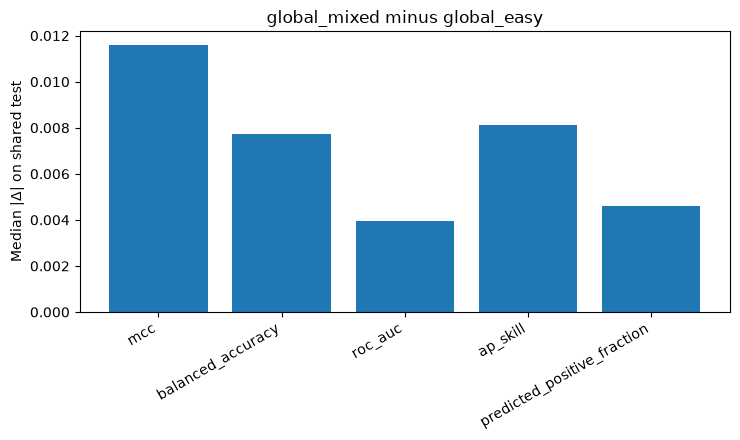

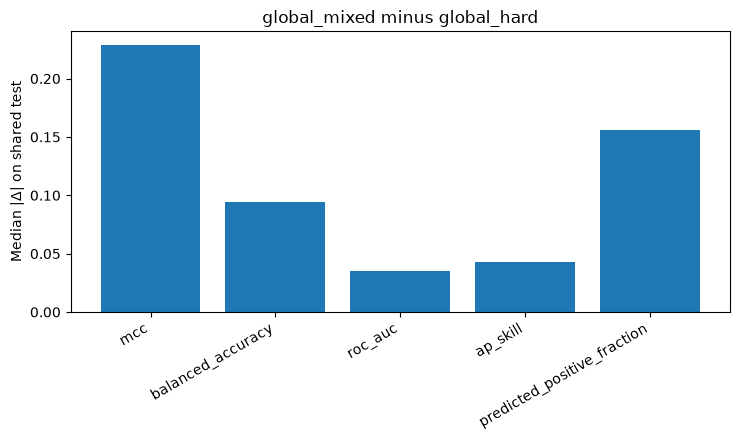

In [12]:
# Visual comparison of absolute effect sizes on identical entities.
effect_rows = []

for (task_a, task_b), g in shared_ext.groupby(["task_A", "task_B"]):
    for metric in [
        "mcc",
        "balanced_accuracy",
        "roc_auc",
        "ap_skill",
        "predicted_positive_fraction",
    ]:
        col = f"delta_{metric}_B_minus_A"
        if col not in g.columns:
            continue

        x = g[col].dropna()

        effect_rows.append(
            {
                "comparison": f"{task_b} minus {task_a}",
                "metric": metric,
                "median_delta": x.median(),
                "mean_delta": x.mean(),
                "median_abs_delta": x.abs().median(),
                "mean_abs_delta": x.abs().mean(),
            }
        )

shared_effects = pd.DataFrame(effect_rows)
display(shared_effects)

for comparison, g in shared_effects.groupby("comparison"):
    plot = g.set_index("metric")["median_abs_delta"]

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.bar(plot.index, plot.values)
    ax.set_ylabel("Median |Δ| on shared test")
    ax.set_title(comparison)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 6. Is `hard → mixed` mainly a threshold/operating-point change?

This is the specific pattern motivating the extension.

If:

- `|Δ MCC|` is large,
- `|Δ balanced accuracy|` is large,
- but `|Δ ROC-AUC|` and `|Δ AP skill|` are small,

then the formulation changes the **decision operating point / score placement** more than the underlying ranking ability.

We do not call this “calibration” unless a dedicated calibration analysis supports that terminology.

In [13]:
hard_mixed = shared_ext[
    shared_ext["task_A"].eq("global_hard")
    & shared_ext["task_B"].eq("global_mixed")
].copy()

diagnostic_table = []

for metric in [
    "mcc",
    "balanced_accuracy",
    "roc_auc",
    "ap",
    "ap_skill",
    "predicted_positive_fraction",
    "mean_score",
    "positive_score_mean",
    "negative_score_mean",
]:
    col = f"delta_{metric}_B_minus_A"

    if col in hard_mixed.columns:
        x = hard_mixed[col].dropna()

        diagnostic_table.append(
            {
                "metric": metric,
                "n": len(x),
                "mean_delta": x.mean(),
                "median_delta": x.median(),
                "median_abs_delta": x.abs().median(),
                "fraction_positive": (x > 0).mean(),
                "fraction_negative": (x < 0).mean(),
            }
        )

diagnostic_table = pd.DataFrame(diagnostic_table)
display(diagnostic_table)

,metric,n,mean_delta,median_delta,median_abs_delta,fraction_positive,fraction_negative
0,mcc,320,-0.245211,-0.229062,0.229062,0.000000,1.000000
1,balanced_accuracy,320,-0.109455,-0.094211,0.094211,0.012500,0.987500
2,roc_auc,320,-0.060786,-0.034929,0.034929,0.006250,0.993750
3,ap,320,-0.026800,-0.013617,0.013617,0.031250,0.968750
4,ap_skill,320,-0.088961,-0.043156,0.043156,0.031250,0.968750
5,predicted_positive_fraction,320,-0.185946,-0.156047,0.156047,0.000000,1.000000
6,mean_score,320,-0.168211,-0.161474,0.161474,0.003125,0.996875
7,positive_score_mean,320,-0.233143,-0.210148,0.210148,0.000000,1.000000
8,negative_score_mean,320,-0.016777,-0.034633,0.062426,0.268750,0.731250


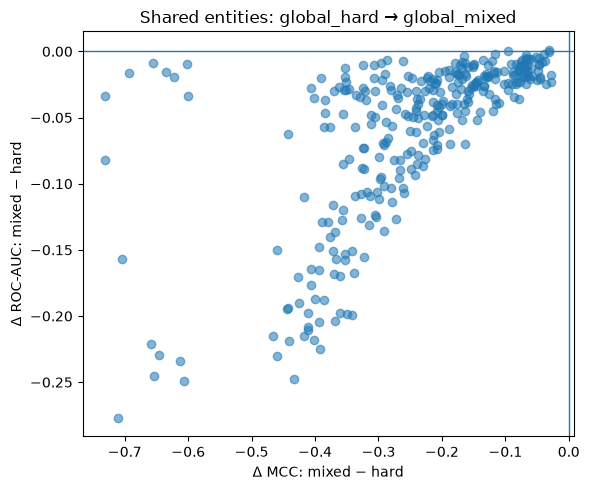

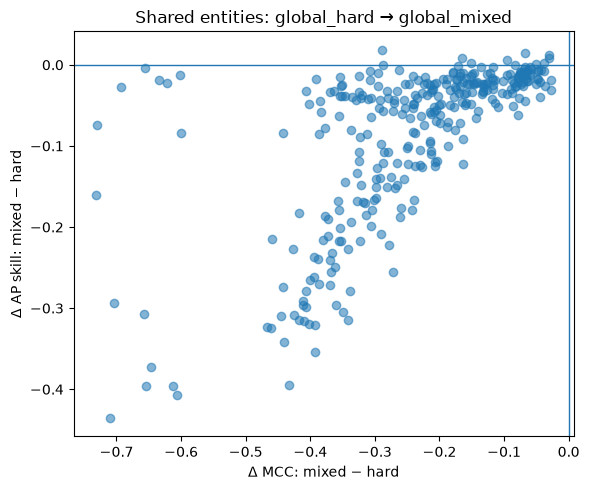

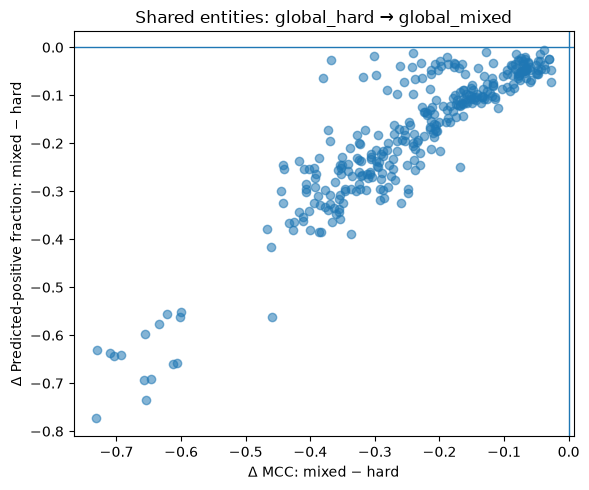

In [14]:
# Scatter: threshold-dependent loss vs ranking/discrimination loss.
pairs = [
    ("delta_mcc_B_minus_A", "delta_roc_auc_B_minus_A", "MCC", "ROC-AUC"),
    ("delta_mcc_B_minus_A", "delta_ap_skill_B_minus_A", "MCC", "AP skill"),
    (
        "delta_mcc_B_minus_A",
        "delta_predicted_positive_fraction_B_minus_A",
        "MCC",
        "Predicted-positive fraction",
    ),
]

for xcol, ycol, xlabel, ylabel in pairs:
    if xcol not in hard_mixed.columns or ycol not in hard_mixed.columns:
        continue

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(hard_mixed[xcol], hard_mixed[ycol], alpha=0.55)
    ax.axhline(0, linewidth=1)
    ax.axvline(0, linewidth=1)
    ax.set_xlabel(f"Δ {xlabel}: mixed − hard")
    ax.set_ylabel(f"Δ {ylabel}: mixed − hard")
    ax.set_title("Shared entities: global_hard → global_mixed")
    plt.tight_layout()
    plt.show()

## 7. Score-distribution shifts on shared entities

In [15]:
score_shift_cols = [
    "delta_positive_score_mean_B_minus_A",
    "delta_negative_score_mean_B_minus_A",
    "delta_predicted_positive_fraction_B_minus_A",
    "score_spearman_A_B",
    "score_mae_A_B",
]

available = [c for c in score_shift_cols if c in hard_mixed.columns]

display(
    hard_mixed.groupby("representation")[available]
    .agg(["mean", "median", "std", "min", "max"])
)

delta_positive_score_mean_B_minus_A                                         delta_negative_score_mean_B_minus_A                                          \
                                              mean    median       std       min       max                                mean    median       std       min       max   
representation                                                                                                                                                           
esm2_t30_150m                            -0.092001 -0.065623  0.062793 -0.264647 -0.018932                           -0.021234 -0.031113  0.041591 -0.089638  0.078958   
esm2_t6_8m                               -0.180408 -0.151213  0.086021 -0.393270 -0.062008                           -0.004926 -0.031763  0.072616 -0.094253  0.170083   
onehot_1024                              -0.383387 -0.368923  0.087483 -0.581214 -0.172795                           -0.010132 -0.034633  0.088710 -0.144590  0.163193   
roxy_48                                  -0.276776 -0.275059  0.080810 -0.420536 -0.139354                           -0.030817 -0.066673  0.098771 -0.151029  0.221278   

               delta_predicted_positive_fraction_B_minus_A                                         score_spearman_A_B                                         score_mae_A_B  \
                                                      mean    median       std       min       max               mean    median       std       min       max          mean   
representation                                                                                                                                                                
esm2_t30_150m                                    -0.066038 -0.053992  0.041522 -0.214286 -0.005199           0.888531  0.902839  0.044771  0.733895  0.949261      0.085695   
esm2_t6_8m                                       -0.127800 -0.114733  0.074616 -0.324074 -0.010399           0.822326  0.821575  0.044312  0.709674  0.910256      0.156489   
onehot_1024                                      -0.352127 -0.300098  0.155695 -0.772622 -0.166378           0.592468  0.590669  0.160630  0.153100  0.932417      0.322942   
roxy_48                                          -0.197818 -0.214601  0.095374 -0.388186 -0.017241           0.780006  0.779243  0.067817  0.593218  0.900177      0.236988   

                                                        
                  median       std       min       max  
representation                                          
esm2_t30_150m   0.067794  0.045935  0.023684  0.210981  
esm2_t6_8m      0.137235  0.057582  0.058253  0.299587  
onehot_1024     0.317443  0.054045  0.200832  0.482329  
roxy_48         0.230393  0.050276  0.131207  0.326097

,representation,delta_positive_score,delta_negative_score,delta_predicted_positive_fraction,score_spearman,score_mae
0,esm2_t30_150m,-0.065623,-0.031113,-0.053992,0.902839,0.067794
1,esm2_t6_8m,-0.151213,-0.031763,-0.114733,0.821575,0.137235
2,onehot_1024,-0.368923,-0.034633,-0.300098,0.590669,0.317443
3,roxy_48,-0.275059,-0.066673,-0.214601,0.779243,0.230393


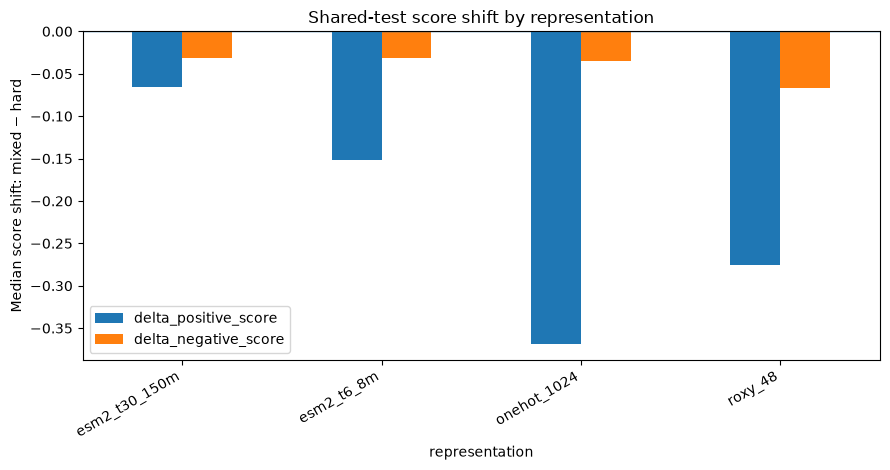

In [16]:
# Representation-level score shifts for hard -> mixed.
rep_score_shift = (
    hard_mixed.groupby("representation", as_index=False)
    .agg(
        delta_positive_score=("delta_positive_score_mean_B_minus_A", "median"),
        delta_negative_score=("delta_negative_score_mean_B_minus_A", "median"),
        delta_predicted_positive_fraction=("delta_predicted_positive_fraction_B_minus_A", "median"),
        score_spearman=("score_spearman_A_B", "median"),
        score_mae=("score_mae_A_B", "median"),
    )
)

display(rep_score_shift)

rep_score_shift.set_index("representation")[
    ["delta_positive_score", "delta_negative_score"]
].plot(kind="bar", figsize=(9, 4.8))

plt.axhline(0, linewidth=1)
plt.ylabel("Median score shift: mixed − hard")
plt.title("Shared-test score shift by representation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 8. R×S dependence of the shared hard→mixed effect


 delta_mcc_B_minus_A


S,90,70,50,30
R,,,,
90,-0.206063,-0.183953,-0.198547,-0.176036
70,-0.204906,-0.225026,-0.267500,-0.247919
50,-0.213687,-0.257032,-0.202011,-0.275492
30,-0.288295,-0.226708,-0.269872,-0.250359


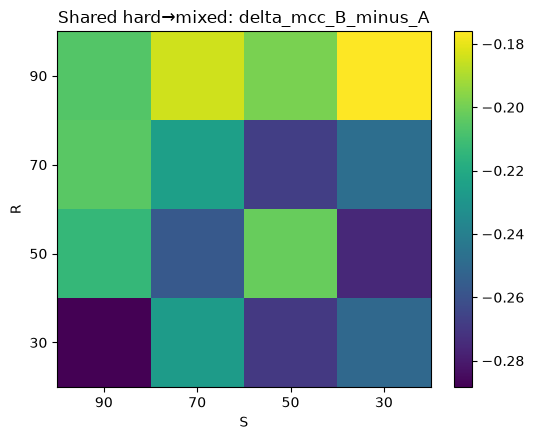


 delta_roc_auc_B_minus_A


S,90,70,50,30
R,,,,
90,-0.017296,-0.018017,-0.032046,-0.020338
70,-0.025105,-0.026668,-0.032778,-0.027866
50,-0.030079,-0.035814,-0.036402,-0.049630
30,-0.059568,-0.048604,-0.044955,-0.037372


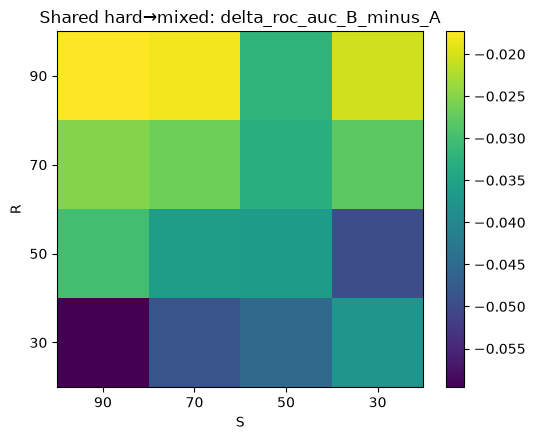


 delta_ap_skill_B_minus_A


S,90,70,50,30
R,,,,
90,-0.028433,-0.023673,-0.040162,-0.020746
70,-0.031022,-0.031336,-0.036920,-0.026618
50,-0.039342,-0.049039,-0.051913,-0.063422
30,-0.081124,-0.065386,-0.054228,-0.047541


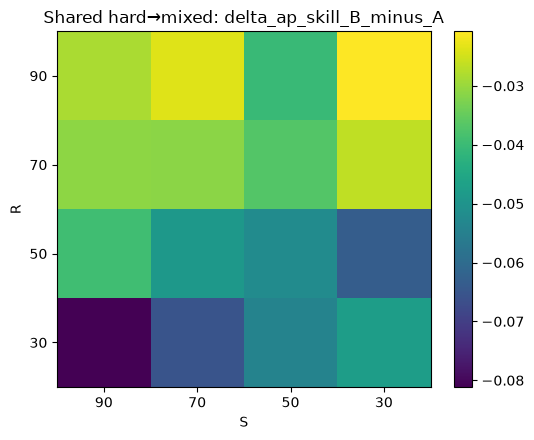


 delta_predicted_positive_fraction_B_minus_A


S,90,70,50,30
R,,,,
90,-0.116639,-0.085789,-0.120307,-0.104328
70,-0.133005,-0.156028,-0.143552,-0.149652
50,-0.157434,-0.151163,-0.141813,-0.174051
30,-0.222222,-0.202532,-0.223214,-0.177489


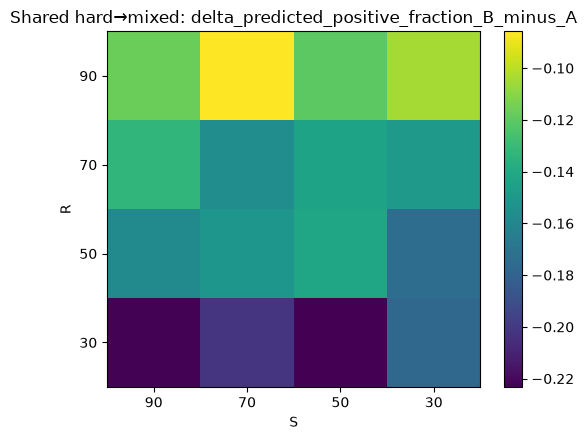

In [17]:
for metric in [
    "delta_mcc_B_minus_A",
    "delta_roc_auc_B_minus_A",
    "delta_ap_skill_B_minus_A",
    "delta_predicted_positive_fraction_B_minus_A",
]:
    if metric not in hard_mixed.columns:
        continue

    surface = (
        hard_mixed.groupby(["R", "S"])[metric]
        .median()
        .reset_index()
        .pivot(index="R", columns="S", values=metric)
        .reindex(index=R_LEVELS, columns=S_LEVELS)
    )

    print("\n", metric)
    display(surface)

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(surface.to_numpy(), aspect="auto")
    ax.set_xticks(range(len(S_LEVELS)), S_LEVELS)
    ax.set_yticks(range(len(R_LEVELS)), R_LEVELS)
    ax.set_xlabel("S")
    ax.set_ylabel("R")
    ax.set_title(f"Shared hard→mixed: {metric}")
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

## 9. Simple diagnostic classification of the hard→mixed effect

This is exploratory and should not be used as a formal hypothesis test.

We flag cases where:

- `|Δ MCC| >= 0.10`
- while `|Δ ROC-AUC| <= 0.02`

as **large threshold-dependent change with relatively stable discrimination**.

The cutoffs are deliberately transparent and editable.

In [18]:
MCC_LARGE = 0.10
AUC_SMALL = 0.02

hard_mixed["large_mcc_small_auc"] = (
    hard_mixed["delta_mcc_B_minus_A"].abs().ge(MCC_LARGE)
    & hard_mixed["delta_roc_auc_B_minus_A"].abs().le(AUC_SMALL)
)

print(
    "Fraction with |ΔMCC| >= %.2f and |ΔROC-AUC| <= %.2f:"
    % (MCC_LARGE, AUC_SMALL),
    hard_mixed["large_mcc_small_auc"].mean(),
)

display(
    hard_mixed.groupby("representation")["large_mcc_small_auc"]
    .agg(["mean", "sum", "count"])
    .rename(columns={"mean": "fraction_flagged"})
)

Fraction with |ΔMCC| >= 0.10 and |ΔROC-AUC| <= 0.02: 0.15625


,fraction_flagged,sum,count
representation,,,
esm2_t30_150m,0.2000,16,80
esm2_t6_8m,0.2875,23,80
onehot_1024,0.0625,5,80
roxy_48,0.0750,6,80


## 10. Native AP-skill versus shared-test AP-skill

In [19]:
# Native easy/mixed and hard/mixed contrasts.
native_skill = ap_skill_pivot.copy()

native_skill_summary = pd.DataFrame(
    [
        {
            "comparison": "mixed_minus_easy",
            "median_native_delta_ap_skill": native_skill["mixed_minus_easy"].median(),
            "fraction_native_positive": (native_skill["mixed_minus_easy"] > 0).mean(),
        },
        {
            "comparison": "mixed_minus_hard",
            "median_native_delta_ap_skill": (-native_skill["hard_minus_mixed"]).median(),
            "fraction_native_positive": ((-native_skill["hard_minus_mixed"]) > 0).mean(),
        },
    ]
)

shared_skill_summary = []

for task_a, task_b in TASK_PAIRS:
    g = shared_ext[
        shared_ext["task_A"].eq(task_a)
        & shared_ext["task_B"].eq(task_b)
    ]

    x = g["delta_ap_skill_B_minus_A"].dropna()

    shared_skill_summary.append(
        {
            "comparison": task_b.replace("global_", "") + "_minus_" + task_a.replace("global_", ""),
            "median_shared_delta_ap_skill": x.median(),
            "fraction_shared_positive": (x > 0).mean(),
        }
    )

shared_skill_summary = pd.DataFrame(shared_skill_summary)

display(
    native_skill_summary.merge(
        shared_skill_summary,
        on="comparison",
        how="outer",
    )
)

,comparison,median_native_delta_ap_skill,fraction_native_positive,median_shared_delta_ap_skill,fraction_shared_positive
0,mixed_minus_easy,-0.004817,0.359375,-0.002762,0.38125
1,mixed_minus_hard,-0.158137,0.000000,-0.043156,0.03125


# 11. RQ1 extension synthesis

After execution, answer these specific questions:

1. Does normalized AP skill recover the same ordering as MCC/ROC-AUC?
2. Was the negative `hard−easy` raw AP-gain contrast mainly a prevalence-headroom artifact?
3. On shared hard/mixed test entities, how large is:
   - ΔMCC?
   - Δbalanced accuracy?
   - ΔROC-AUC?
   - ΔAP skill?
4. Is the hard→mixed difference mostly discrimination/ranking, operating point, or both?
5. Does predicted-positive fraction shift strongly?
6. Are positive scores, negative scores, or both displaced?
7. Does the answer differ by representation?
8. Does the operating-point effect itself vary across R×S?
9. Does shared-test normalized AP skill support the same task-definition conclusion as native-test AP skill?

### Terminology guardrail

If ROC-AUC/AP skill remain nearly unchanged while MCC/predicted-positive fraction change strongly, describe the phenomenon as:

> **operating-point / score-distribution sensitivity to task formulation**

and not as “calibration” unless a dedicated calibration analysis is performed.

In [20]:
# Compact final evidence table.

final_rows = []

for contrast in ["hard_minus_easy", "mixed_minus_easy", "hard_minus_mixed"]:
    x = ap_skill_pivot[contrast].dropna()

    final_rows.append(
        {
            "analysis": "native_AP_skill",
            "comparison": contrast,
            "median_delta": x.median(),
            "mean_delta": x.mean(),
            "fraction_positive": (x > 0).mean(),
            "n": len(x),
        }
    )

for (task_a, task_b), g in shared_ext.groupby(["task_A", "task_B"]):
    for metric in ["mcc", "balanced_accuracy", "roc_auc", "ap_skill", "predicted_positive_fraction"]:
        col = f"delta_{metric}_B_minus_A"
        if col not in g.columns:
            continue

        x = g[col].dropna()

        final_rows.append(
            {
                "analysis": "shared_test",
                "comparison": f"{task_b}_minus_{task_a}",
                "metric": metric,
                "median_delta": x.median(),
                "mean_delta": x.mean(),
                "fraction_positive": (x > 0).mean(),
                "n": len(x),
            }
        )

final_evidence = pd.DataFrame(final_rows)
display(final_evidence)

OUTPUT_PATH = CACHE_DIR / "rq1_extension_evidence_summary.tsv"
final_evidence.to_csv(OUTPUT_PATH, sep="\t", index=False)
print("Saved:", OUTPUT_PATH)

,analysis,comparison,median_delta,mean_delta,fraction_positive,n,metric
0,native_AP_skill,hard_minus_easy,0.153011,0.208326,1.000000,320,NaN
1,native_AP_skill,mixed_minus_easy,-0.004817,-0.004770,0.359375,320,NaN
2,native_AP_skill,hard_minus_mixed,0.158137,0.213096,1.000000,320,NaN
3,shared_test,global_mixed_minus_global_easy,-0.003874,-0.005479,0.346875,320,mcc
4,shared_test,global_mixed_minus_global_easy,-0.004090,-0.004199,0.343750,320,balanced_accuracy
5,shared_test,global_mixed_minus_global_easy,-0.002087,-0.003121,0.290625,320,roc_auc
6,shared_test,global_mixed_minus_global_easy,-0.002762,-0.002877,0.381250,320,ap_skill
7,shared_test,global_mixed_minus_global_easy,-0.002178,-0.001756,0.331250,320,predicted_positive_fraction
8,shared_test,global_mixed_minus_global_hard,-0.229062,-0.245211,0.000000,320,mcc
9,shared_test,global_mixed_minus_global_hard,-0.094211,-0.109455,0.012500,320,balanced_accuracy


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq1_extension_evidence_summary.tsv
